# Deutsch-Jozsa Algorithm

The Deutsch-Jozsa algorithm extends Deutsch's algorithm to a function f of **n** bits.
f is promised to be either **constant** (the same output for all 2<sup>n</sup> inputs)
or **balanced** (0 for half the inputs and 1 for the other half).
A classical computer may need 2<sup>n−1</sup> + 1 calls to be sure. The quantum circuit needs **one**.

Steps: prepare |0…0⟩|1⟩ → H on all qubits → oracle → H on the n input qubits → measure them.

Oracles used here:
- **constant:** f(x) = 0 (nothing) or f(x) = 1 (X on the output qubit)
- **balanced:** f(x) = b·x mod 2 for a non-zero bit string b (one CNOT for each 1 in b)

**Inputs:** n, the oracle type and its output value or bit string b.
**Expected:** all zeros → f is CONSTANT, anything else → f is BALANCED
(for the balanced oracle the measured string equals b).
The second cell saves the circuit diagram as a PNG.


Counts: {'1111': 1024}
Measured (q[n-1]...q[0]): 1111
Function is: BALANCED
Correct: True


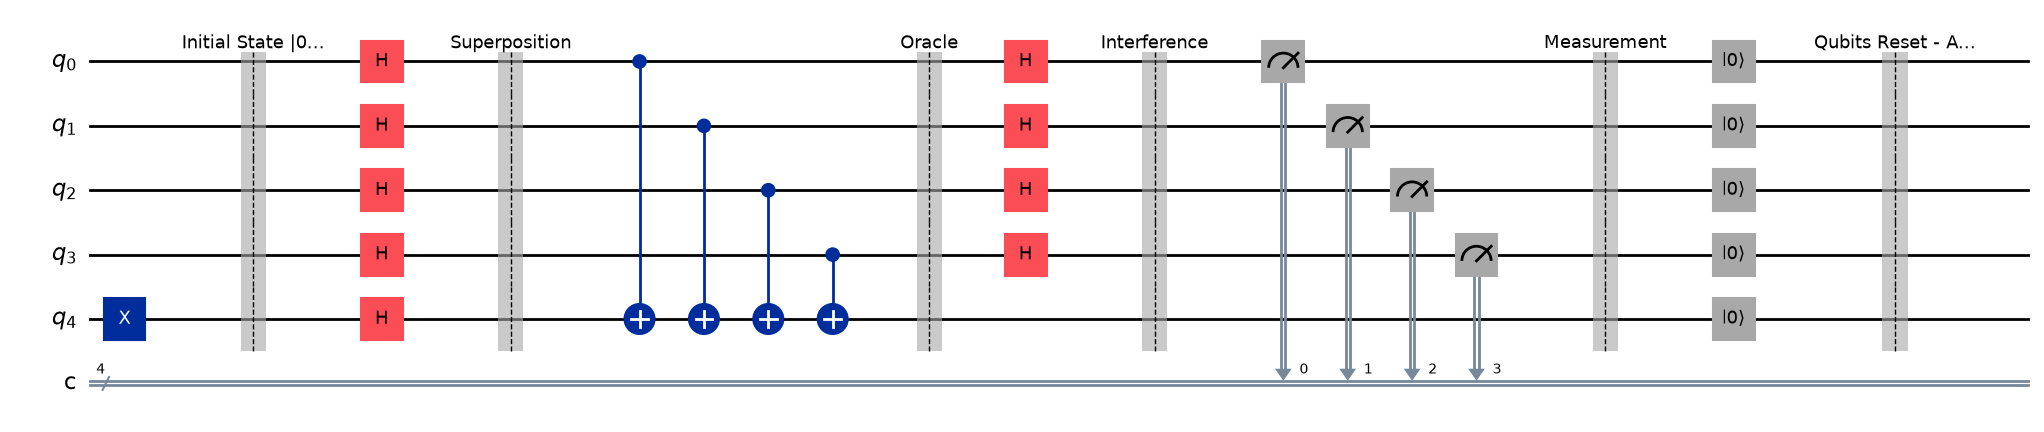

In [7]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator

# Inputs
n = int(input("Enter number of input qubits n: "))
oracle_type = input("Enter oracle type (constant / balanced): ").strip().lower()

if oracle_type == "constant":
    value = input("Enter constant output f(x) (0 or 1): ")
    if value not in ["0", "1"]:
        raise ValueError("Enter 0 or 1.")
elif oracle_type == "balanced":
    b = input(f"Enter a non-zero {n}-bit string b, f(x) = b.x mod 2: ")
    if len(b) != n or set(b) - {"0", "1"} or "1" not in b:
        raise ValueError(f"Enter a {n}-bit string with at least one 1.")
else:
    raise ValueError("Enter constant or balanced.")

# Registers: q[0]..q[n-1] = input x, q[n] = output y
q = QuantumRegister(n + 1, 'q')
c = ClassicalRegister(n, 'c')

qc = QuantumCircuit(q, c)

# Prepare |0...0>|1>
qc.x(q[n])
qc.barrier(label="Initial State |0...0>|1>")

# Superposition
for i in range(n + 1):
    qc.h(q[i])
qc.barrier(label="Superposition")

# Oracle: |x>|y> -> |x>|y XOR f(x)>
if oracle_type == "constant":
    if value == "1":
        qc.x(q[n])
else:
    # b is written q[n-1]...q[0], like Qiskit results
    for i in range(n):
        if b[n - 1 - i] == "1":
            qc.cx(q[i], q[n])
qc.barrier(label="Oracle")

# Interference
for i in range(n):
    qc.h(q[i])
qc.barrier(label="Interference")

# Measurement
for i in range(n):
    qc.measure(q[i], c[i])
qc.barrier(label="Measurement")

# Reset all qubits after measurement
for i in range(n + 1):
    qc.reset(q[i])
qc.barrier(label="Qubits Reset - Available for Reuse")

# Run circuit
result = AerSimulator().run(qc, shots=1024).result()
counts = result.get_counts()
print("\nCounts:", counts)

measured = max(counts, key=counts.get)
answer = "CONSTANT" if measured == "0" * n else "BALANCED"

print("Measured (q[n-1]...q[0]):", measured)
print("Function is:", answer)
print("Correct:", answer == oracle_type.upper())

# Draw circuit
qc.draw(output='mpl', fold=-1, scale=1.0)

In [2]:
fig = qc.draw(output="mpl", fold=-1, scale=1.0)
fig.savefig("4_2_DeutschJozsa.png", dpi=300, bbox_inches="tight")